In [2]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

import torch
import matplotlib.pyplot as plt
import matplotlib.patches as patches

from torchmetrics.detection.mean_ap import MeanAveragePrecision

from datasets.coin_detection_dataset import CoinDetectionDataset
from models.custom_detector import CustomDetector

In [ ]:
detector = CustomDetector(
    background_checkpoint=(PROJECT_ROOT / "checkpoints/background_best.pth"),
    regressor_checkpoint=(PROJECT_ROOT / "checkpoints/regressor_best.pth"),
    classifier_checkpoint=(PROJECT_ROOT / "checkpoints/classifier_best.pth"))

In [6]:
val_ds = CoinDetectionDataset(
    PROJECT_ROOT / "data/raw/val.pkl"
)

sample = val_ds[0]

image = sample["image"]

detections = detector.predict(image)

print("detection num:", len(detections))

for detection in detections:
    print(detection)

detection num: 8
(295.8909912109375, 432.988525390625, 362.8103942871094, 501.3546142578125, 6, 0.9999676942825317)
(362.5456237792969, 298.75421142578125, 414.6754150390625, 351.29339599609375, 0, 0.9987298846244812)
(424.16107177734375, 247.5234832763672, 478.9563293457031, 301.8995361328125, 1, 0.9981891512870789)
(267.64483642578125, 319.6639404296875, 322.2200927734375, 373.2747802734375, 1, 0.99753737449646)
(155.91836547851562, 276.61199951171875, 215.30120849609375, 334.4436950683594, 2, 0.9972680807113647)
(193.23431396484375, 407.3550109863281, 250.7925567626953, 465.01849365234375, 4, 0.9938939213752747)
(90.84402465820312, 351.4374084472656, 168.09107971191406, 428.00445556640625, 8, 0.9930068254470825)
(399.6136169433594, 424.058837890625, 469.19195556640625, 492.55560302734375, 5, 0.8703802227973938)


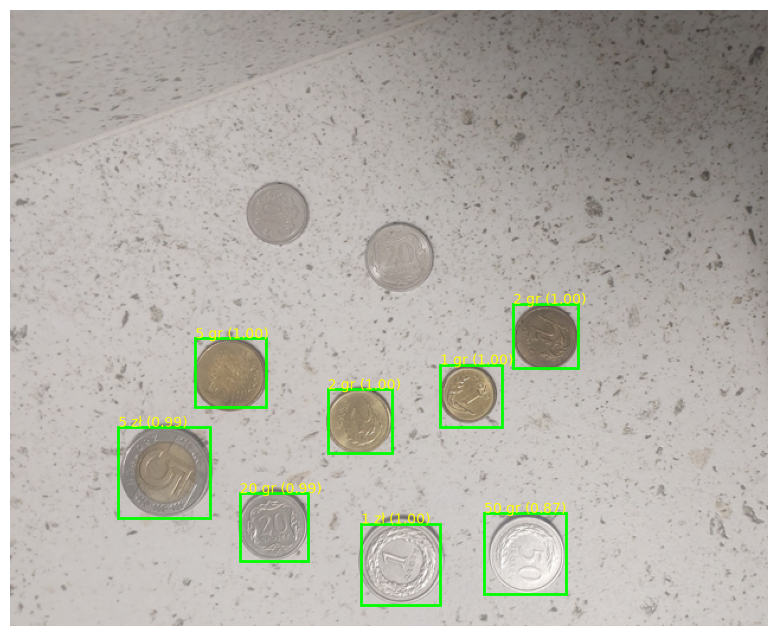

In [7]:
CLASS_NAMES = [
    "1 gr",
    "2 gr",
    "5 gr",
    "10 gr",
    "20 gr",
    "50 gr",
    "1 zł",
    "2 zł",
    "5 zł",
]

fig, ax = plt.subplots(figsize=(12, 8))

ax.imshow(image.permute(1, 2, 0))

for x1, y1, x2, y2, label, confidence in detections:
    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        linewidth=2,
        edgecolor="lime",
        facecolor="none",
    )

    ax.add_patch(rectangle)

    ax.text(
        x1,
        y1,
        f"{CLASS_NAMES[label]} ({confidence:.2f})",
        color="yellow",
    )

plt.axis("off")
plt.show()

In [8]:
metric = MeanAveragePrecision(
    box_format="xyxy",
    iou_type="bbox",
)

for sample in val_ds:
    detections = detector.predict(sample["image"])

    if detections:
        pred_boxes = torch.tensor(
            [d[:4] for d in detections],
            dtype=torch.float32,
        )

        pred_labels = torch.tensor(
            [d[4] for d in detections],
            dtype=torch.long,
        )

        pred_scores = torch.tensor(
            [d[5] for d in detections],
            dtype=torch.float32,
        )
    else:
        pred_boxes = torch.empty((0, 4))
        pred_labels = torch.empty((0,), dtype=torch.long)
        pred_scores = torch.empty((0,))

    predictions = [{
        "boxes": pred_boxes,
        "labels": pred_labels,
        "scores": pred_scores,
    }]

    targets = [{
        "boxes": sample["boxes"],
        "labels": sample["labels"],
    }]

    metric.update(predictions, targets)

results = metric.compute()

print("mAP@0.5:0.95:", results["map"].item())
print("mAP@0.5:", results["map_50"].item())
print("mAP@0.75:", results["map_75"].item())

mAP@0.5:0.95: 0.5751584768295288
mAP@0.5: 0.7809950709342957
mAP@0.75: 0.6888821721076965
